# Hof Lecture | Diagnostic Analytics: Late Deliveries
**Student notebook — start at BEFORE, then make each marked change.**

**Business question:** Which process stages deserve investigation when shipments miss their delivery promise?

**Learning objectives:** Reconstruct total lead time from stage durations; compare late rates and simplified OTIF; interpret a Pareto of attributed contributors; and distinguish process changes from reporting-policy changes.

Complete the baseline and **all five experiments in order**. For each: inspect **BEFORE**, make the marked **CHANGE**, inspect **AFTER**, then answer **THINK**. Run each experiment once at its starting setting and again after editing it. Each experiment independently starts from `baseline`; changes do not accumulate. No time limit is imposed.

Run setup from top to bottom. Teacher functions are supplied; edit only the short experiment cells marked `# <-- CHANGE HERE`.

**Important:** This is synthetic stage-duration data, not real company records or a full timestamped event log. RootCause is a heuristic attribution, not proof of causation. Changing an assumed stage duration is a controlled simulation; it does not establish real-world causal effects.


## Dataset and KPI definitions
We retain the original **500 shipments**, random seed **7**, mode probabilities Road/Air/Sea = **60%/20%/20%**, and the original generation distributions. These are a separate synthetic case from the 600-shipment descriptive notebook.

Each row represents a simplified shipment with sequential, non-overlapping stages measured in **calendar days**. Stage order is a teaching simplification rather than a universal logistics process. Depart means waiting after picking until dispatch, so it does not overlap Pick. Customs means elapsed clearance time, not excess delay automatically.

| Column | Meaning |
|---|---|
| Shipment_ID | Unique shipment identifier |
| Mode | Road / Air / Sea (same concept as Transport_Mode in the descriptive case) |
| OrderDate | Synthetic order date; actual stage-event timestamps are not generated |
| Pick | Picking duration, days |
| Depart | Post-picking wait until dispatch, days |
| Customs | Clearance duration, days |
| Linehaul | Main transport duration, days |
| LastMile | Final delivery duration, days |
| LeadTime | Pick + Depart + Customs + Linehaul + LastMile, days |
| SLA | Promised lead-time limit: Air 4, Road 7, Sea 18 days |
| Late_Strict | LeadTime > SLA, retained as the strict reference |
| Tolerance_days | Reporting tolerance: 0 except when changed in Experiment 5 |
| Late | LeadTime > SLA + Tolerance_days |
| On_Time / OTIF | Both equal NOT Late; classroom on-time approximation |
| RootCause | Stage with greatest positive excess over the supplied benchmarks; None if no excess |

**Simplified OTIF (%)** = 100 × mean(NOT Late). Completeness is not modeled; full operational OTIF also requires delivery in full. With tolerance=1, the reported KPI is explicitly **tolerance-adjusted**, not strict SLA compliance. Late_Strict preserves that distinction.

Stage durations are recorded to two decimals. Total lead time and lateness are computed from these recorded values consistently. This corrects the original mismatch between hidden unrounded durations and displayed data.

**Signed difference = AFTER − BEFORE.** Percentage KPI differences use **percentage points**. A negative change in late rate is favorable; a negative change in OTIF is unfavorable. Values are rounded only for display.


## How RootCause is assigned
The original notebook compares stage durations with these common benchmarks:

| Stage | Benchmark (days) |
|---|---:|
| Pick | 0.60 |
| Depart | 0.30 |
| Customs | 1.00 |
| Linehaul | 2.50 |
| LastMile | 0.80 |

For each row, calculate **duration − benchmark**. Choose the stage with the largest **positive** excess. If none is positive, assign `None`. Ties use the order Pick, Depart, Customs, Linehaul, LastMile. The label is calculated for all rows, but the Pareto counts **only currently late shipments**.

**Limitation:** These inherited benchmarks are not mode-specific or calibrated. Sea linehaul is generated around 10 days but is compared with 2.5 days, so Sea is predisposed to receive a Linehaul label. The benchmark sums do not define each mode's SLA. A large excess is an investigation signal, not proof that this stage alone caused a missed SLA. Real diagnosis needs validated process targets, timestamps and operational evidence.

The Pareto sorts attributed late-shipment counts from largest to smallest. Its cumulative line uses the **number of late shipments** as denominator, not all 500 shipments. A changed chart can reflect different stage durations, changed labels or a changed set of shipments classified late. Always inspect counts and rates together.

A late row can have RootCause=`None`: none of its stages exceeds these common benchmarks, but their sum can still exceed its mode-specific SLA. The benchmarks sum to 5.2 days, while Air SLA is 4 days. Retain None in the Pareto so late counts reconcile.


## Teacher setup — run, no edits needed

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

In [2]:
# TEACHER SETUP — RUN THIS CELL; NO EDITS NEEDED.
STAGE_COLUMNS = ["Pick", "Depart", "Customs", "Linehaul", "LastMile"]
# Original notebook's common benchmarks, retained for continuity (calendar days).
# They are teaching assumptions, not calibrated mode-specific process targets.
BENCHMARKS = {"Pick": 0.6, "Depart": 0.3, "Customs": 1.0,
              "Linehaul": 2.5, "LastMile": 0.8}

def evaluate(data, tolerance_days=0.0):
    """Recalculate every derived field; never modify the input dataframe."""
    if tolerance_days < 0:
        raise ValueError("Tolerance must be nonnegative.")
    x = data.copy(deep=True)
    # Stage durations are recorded to 0.01 day; integer hundredths prevent
    # floating-point summation from classifying exact SLA equality as late.
    hundredths = np.rint(x[STAGE_COLUMNS].to_numpy(dtype=float) * 100).astype(int)
    x[STAGE_COLUMNS] = hundredths / 100
    x["LeadTime"] = hundredths.sum(axis=1) / 100
    x["Late_Strict"] = x.LeadTime > x.SLA
    x["Tolerance_days"] = float(tolerance_days)
    x["Late"] = x.LeadTime > (x.SLA + tolerance_days)
    x["On_Time"] = ~x.Late
    x["OTIF"] = x.On_Time  # Classroom on-time approximation; no in-full data.
    # Largest positive excess over the supplied COMMON stage benchmarks.
    excess = (x[STAGE_COLUMNS] - pd.Series(BENCHMARKS)).round(2)
    x["RootCause"] = excess.idxmax(axis=1)
    x.loc[excess.max(axis=1) <= 0, "RootCause"] = "None"
    # idxmax resolves ties in STAGE_COLUMNS order. Attribution is calculated
    # for all rows; the Pareto includes ONLY rows meeting the current Late rule.
    return x

def create_shipments(n=500, seed=7):
    rng = np.random.default_rng(seed)
    
    # --- Create staged event dataset ---
    N = n
    mode = rng.choice(["Road","Air","Sea"], p=[0.6,0.2,0.2], size=N)
    order_day = pd.to_datetime("2025-01-01") + pd.to_timedelta(rng.integers(0,60,size=N), unit="D")
    
    # Stage durations (in days) with mode effects
    pick = rng.normal(0.5, 0.2, size=N).clip(0.1,2.0)
    depart = rng.normal(0.2, 0.1, size=N).clip(0.05,1.0)
    customs = np.where(mode=="Sea", rng.normal(3.0,1.2,size=N), rng.normal(0.6,0.4,size=N)).clip(0,8)
    linehaul = np.where(mode=="Air", rng.normal(1.8,0.5,size=N),
                np.where(mode=="Road", rng.normal(3.0,1.0,size=N), rng.normal(10,3,size=N))).clip(0.5,20)
    lastmile = rng.normal(0.7,0.3,size=N).clip(0.2,3.0)
    
    data = pd.DataFrame({
        "Shipment_ID": np.arange(1, N + 1), "Mode": mode, "OrderDate": order_day,
        "Pick": pick.round(2), "Depart": depart.round(2),
        "Customs": customs.round(2), "Linehaul": linehaul.round(2),
        "LastMile": lastmile.round(2),
        "SLA": np.where(mode == "Air", 4, np.where(mode == "Road", 7, 18))})
    return evaluate(data)

def kpis(data):
    return pd.Series({"Shipments": len(data), "Late shipments": int(data.Late.sum()),
                      "Late rate (%)": 100 * data.Late.mean(),
                      "OTIF (%)": 100 * data.OTIF.mean(),
                      "Mean lead time (days)": data.LeadTime.mean()}, name="Value")

def by_mode(data):
    return data.groupby("Mode").agg(
        Shipments=("Shipment_ID", "size"), Late_shipments=("Late", "sum"),
        Mean_lead_time_days=("LeadTime", "mean"), Mean_SLA_days=("SLA", "mean"),
        OTIF_pct=("OTIF", lambda v: 100 * v.mean()))

def pareto_table(data):
    counts = data.loc[data.Late, "RootCause"].value_counts()
    table = counts.rename_axis("Attributed stage").reset_index(name="Late shipments")
    # Explicit deterministic tie order for equal counts.
    order = {s: i for i, s in enumerate(STAGE_COLUMNS + ["None"])}
    table["_order"] = table["Attributed stage"].map(order)
    table = table.sort_values(["Late shipments", "_order"], ascending=[False, True]).drop(columns="_order").reset_index(drop=True)
    total = int(data.Late.sum())
    table["Share of late shipments (%)"] = 100 * table["Late shipments"] / total if total else 0.0
    table["Cumulative share (%)"] = table["Share of late shipments (%)"].cumsum()
    return table

def plot_pareto(data, title):
    table = pareto_table(data)
    fig, ax = plt.subplots(figsize=(7, 3.6))
    ax.set_title(title)
    ax.set_xlabel("Attributed stage (heuristic)")
    ax.set_ylabel("Number of late shipments")
    if len(table):
        pos = np.arange(len(table))
        ax.bar(pos, table["Late shipments"], color="#377eb8")
        ax.set_xticks(pos, table["Attributed stage"])
        ax2 = ax.twinx()
        ax2.plot(pos, table["Cumulative share (%)"], color="#e6550d", marker="o")
        ax2.set_ylabel("Cumulative share of late shipments (%)")
        ax2.set_ylim(0, 105)
    else:
        ax.text(0.5, 0.5, "No late shipments under this rule", ha="center", transform=ax.transAxes)
    fig.tight_layout(); plt.show()

def show_baseline(data):
    display(kpis(data).to_frame().round(2))
    display(by_mode(data).round(2))
    display(pareto_table(data).round(2))
    plot_pareto(data, "Baseline: attribution among late shipments")

def compare(before, after, title):
    table = pd.concat([kpis(before).rename("BEFORE"), kpis(after).rename("AFTER")], axis=1)
    table["Difference (AFTER - BEFORE)"] = table.AFTER - table.BEFORE
    table["Difference unit"] = ["shipments", "shipments", "percentage points", "percentage points", "days"]
    print(title)
    display(table.round(2))
    print("AFTER: results by mode")
    display(by_mode(after).round(2))
    a = pareto_table(before).set_index("Attributed stage")["Late shipments"]
    b = pareto_table(after).set_index("Attributed stage")["Late shipments"]
    causes = pd.concat([a.rename("BEFORE late count"), b.rename("AFTER late count")], axis=1).fillna(0).astype(int)
    causes["Difference"] = causes.iloc[:, 1] - causes.iloc[:, 0]
    print("Attribution counts among late shipments (denominator can change)")
    display(causes)
    print("AFTER: sorted Pareto table")
    display(pareto_table(after).round(2))
    plot_pareto(after, title + ": attribution among late shipments")

def add_stage_delay(data, mode, stage, days):
    if stage not in STAGE_COLUMNS or days < 0:
        raise ValueError("Choose a known stage and nonnegative added duration.")
    x = data.copy(deep=True)
    x.loc[x.Mode == mode, stage] += days
    return evaluate(x)

def change_sea_sla(data, days):
    if days <= 0: raise ValueError("SLA must be positive.")
    x = data.copy(deep=True)
    x.loc[x.Mode == "Sea", "SLA"] = days
    return evaluate(x)

def improve_warehouse(data, reduction):
    if not 0 <= reduction <= 1: raise ValueError("Use a reduction from 0 to 1.")
    x = data.copy(deep=True)
    x[["Pick", "Depart"]] = (x[["Pick", "Depart"]] * (1 - reduction)).round(2)
    return evaluate(x)


## Baseline — inspect BEFORE starting the experiments
Read the first rows, overall and per-mode KPI tables, and baseline Pareto.

,Shipment_ID,Mode,OrderDate,Pick,Depart,Customs,Linehaul,LastMile,SLA,LeadTime,Late_Strict,Tolerance_days,Late,On_Time,OTIF,RootCause
0,1,Air,2025-03-01,0.20,0.27,0.64,1.63,0.20,4,2.94,False,0.0,False,True,True,None
1,2,Sea,2025-01-26,0.56,0.05,3.97,10.92,0.20,18,15.70,False,0.0,False,True,True,Linehaul
2,3,Air,2025-01-17,0.48,0.19,0.31,1.54,0.94,4,3.46,False,0.0,False,True,True,LastMile
3,4,Road,2025-02-19,0.44,0.23,1.35,1.81,0.91,7,4.74,False,0.0,False,True,True,Customs
4,5,Road,2025-01-28,0.49,0.16,0.12,2.35,0.20,7,3.32,False,0.0,False,True,True,None


,Value
Shipments,500.00
Late shipments,62.00
Late rate (%),12.40
OTIF (%),87.60
Mean lead time (days),6.66


,Shipments,Late_shipments,Mean_lead_time_days,Mean_SLA_days,OTIF_pct
Mode,,,,,
Air,102,41,3.83,4.0,59.80
Road,294,8,4.99,7.0,97.28
Sea,104,13,14.15,18.0,87.50


,Attributed stage,Late shipments,Share of late shipments (%),Cumulative share (%)
0,Linehaul,26,41.94,41.94
1,LastMile,17,27.42,69.35
2,Pick,7,11.29,80.65
3,Customs,6,9.68,90.32
4,None,5,8.06,98.39
5,Depart,1,1.61,100.00


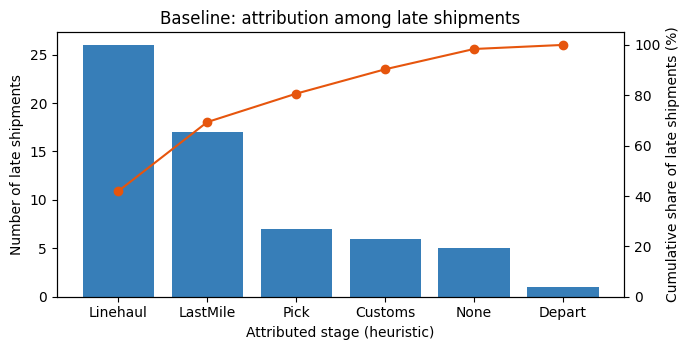

In [3]:
baseline = create_shipments(n=500, seed=7)
display(baseline.head())
show_baseline(baseline)  # <-- OBSERVE OUTPUT

### Lead-time distribution by mode
Compare variability and typical durations. Each mode has a different SLA; raw speed alone does not determine its on-time rate.

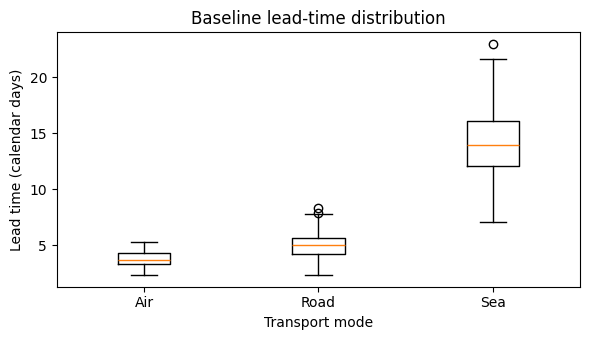

In [4]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.boxplot([baseline.loc[baseline.Mode == m, "LeadTime"] for m in ["Air", "Road", "Sea"]])
ax.set_xticks([1, 2, 3], ["Air", "Road", "Sea"])
ax.set_xlabel("Transport mode"); ax.set_ylabel("Lead time (calendar days)")
ax.set_title("Baseline lead-time distribution")
fig.tight_layout(); plt.show()  # <-- OBSERVE OUTPUT

**THINK:** Which attributed stage is most frequent among late shipments? Does that prove its physical root cause?

**Your answer:** ...

## Experiment 1 — Customs impact
**Business question:** How does extra Sea clearance time affect lateness and attribution?

**BEFORE:** No extra customs duration.

**CHANGE:** Change SEA_CUSTOMS_EXTRA_DAYS from 0 to 2. Add 2 days to Customs for every Sea row, raising the Sea average by exactly 2 days. Recompute LeadTime, Late, OTIF, RootCause and Pareto.

**AFTER:** Inspect the signed KPI comparison, per-mode table, attribution-count comparison and updated Pareto.

Experiment 1 — Sea customs


,BEFORE,AFTER,Difference (AFTER - BEFORE),Difference unit
Shipments,500.00,500.00,0.0,shipments
Late shipments,62.00,62.00,0.0,shipments
Late rate (%),12.40,12.40,0.0,percentage points
OTIF (%),87.60,87.60,0.0,percentage points
Mean lead time (days),6.66,6.66,0.0,days


AFTER: results by mode


,Shipments,Late_shipments,Mean_lead_time_days,Mean_SLA_days,OTIF_pct
Mode,,,,,
Air,102,41,3.83,4.0,59.80
Road,294,8,4.99,7.0,97.28
Sea,104,13,14.15,18.0,87.50


Attribution counts among late shipments (denominator can change)


,BEFORE late count,AFTER late count,Difference
Attributed stage,,,
Linehaul,26,26,0
LastMile,17,17,0
Pick,7,7,0
Customs,6,6,0
None,5,5,0
Depart,1,1,0


AFTER: sorted Pareto table


,Attributed stage,Late shipments,Share of late shipments (%),Cumulative share (%)
0,Linehaul,26,41.94,41.94
1,LastMile,17,27.42,69.35
2,Pick,7,11.29,80.65
3,Customs,6,9.68,90.32
4,None,5,8.06,98.39
5,Depart,1,1.61,100.00


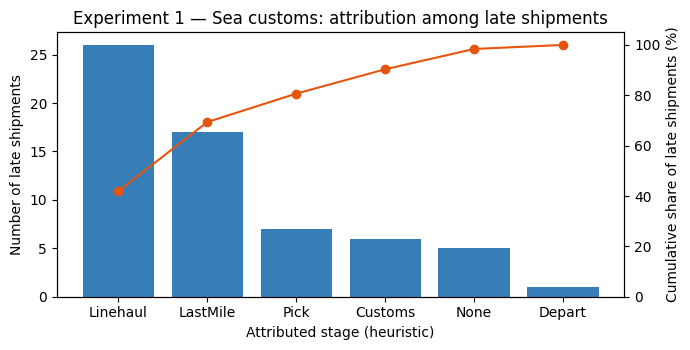

In [5]:
SEA_CUSTOMS_EXTRA_DAYS = 0  # <-- CHANGE HERE: 0 -> 2 days
customs_after = add_stage_delay(baseline, "Sea", "Customs", SEA_CUSTOMS_EXTRA_DAYS)
compare(baseline, customs_after, "Experiment 1 — Sea customs")  # <-- OBSERVE OUTPUT

**THINK**

1. How do Sea mean lead time and late count change?
2. Does Customs necessarily become the most frequent attribution? Use the Pareto.
3. How do the common benchmarks limit a root-cause claim?

**Your answers:**

1. ...
2. ...
3. ...

## Experiment 2 — Linehaul disruption
**Business question:** How does an extra Road linehaul day affect service?

**BEFORE:** No extra Road linehaul duration.

**CHANGE:** Change ROAD_LINEHAUL_EXTRA_DAYS from 0 to 1. Add 1 day to Road Linehaul; leave other modes and stages fixed.

**AFTER:** Inspect the signed KPI comparison, per-mode table, attribution-count comparison and updated Pareto.

Experiment 2 — Road linehaul


,BEFORE,AFTER,Difference (AFTER - BEFORE),Difference unit
Shipments,500.00,500.00,0.0,shipments
Late shipments,62.00,62.00,0.0,shipments
Late rate (%),12.40,12.40,0.0,percentage points
OTIF (%),87.60,87.60,0.0,percentage points
Mean lead time (days),6.66,6.66,0.0,days


AFTER: results by mode


,Shipments,Late_shipments,Mean_lead_time_days,Mean_SLA_days,OTIF_pct
Mode,,,,,
Air,102,41,3.83,4.0,59.80
Road,294,8,4.99,7.0,97.28
Sea,104,13,14.15,18.0,87.50


Attribution counts among late shipments (denominator can change)


,BEFORE late count,AFTER late count,Difference
Attributed stage,,,
Linehaul,26,26,0
LastMile,17,17,0
Pick,7,7,0
Customs,6,6,0
None,5,5,0
Depart,1,1,0


AFTER: sorted Pareto table


,Attributed stage,Late shipments,Share of late shipments (%),Cumulative share (%)
0,Linehaul,26,41.94,41.94
1,LastMile,17,27.42,69.35
2,Pick,7,11.29,80.65
3,Customs,6,9.68,90.32
4,None,5,8.06,98.39
5,Depart,1,1.61,100.00


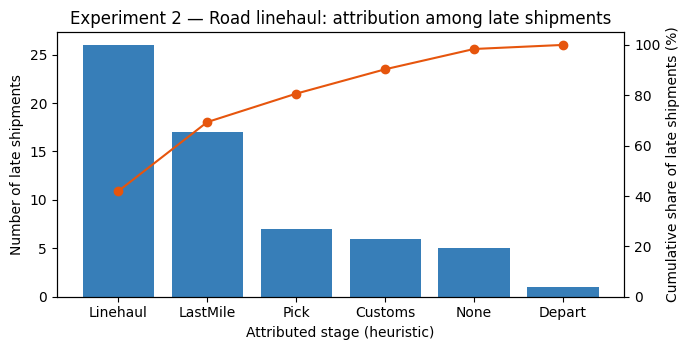

In [6]:
ROAD_LINEHAUL_EXTRA_DAYS = 0  # <-- CHANGE HERE: 0 -> 1 day
linehaul_after = add_stage_delay(baseline, "Road", "Linehaul", ROAD_LINEHAUL_EXTRA_DAYS)
compare(baseline, linehaul_after, "Experiment 2 — Road linehaul")  # <-- OBSERVE OUTPUT

**THINK**

1. How many additional Road shipments become late?
2. What is the signed change in overall simplified OTIF, in percentage points?
3. Why does this exercise not establish whether the real disruption was traffic or another cause?

**Your answers:**

1. ...
2. ...
3. ...

## Experiment 3 — SLA relaxation
**Business question:** Can a KPI improve without faster deliveries?

**BEFORE:** Sea SLA = 18 days.

**CHANGE:** Change SEA_SLA_DAYS from 18 to 20. Durations, total lead times and per-row attribution remain unchanged; re-evaluate the late population.

**AFTER:** Inspect the signed KPI comparison, per-mode table, attribution-count comparison and updated Pareto.

Experiment 3 — Sea SLA


,BEFORE,AFTER,Difference (AFTER - BEFORE),Difference unit
Shipments,500.00,500.00,0.0,shipments
Late shipments,62.00,62.00,0.0,shipments
Late rate (%),12.40,12.40,0.0,percentage points
OTIF (%),87.60,87.60,0.0,percentage points
Mean lead time (days),6.66,6.66,0.0,days


AFTER: results by mode


,Shipments,Late_shipments,Mean_lead_time_days,Mean_SLA_days,OTIF_pct
Mode,,,,,
Air,102,41,3.83,4.0,59.80
Road,294,8,4.99,7.0,97.28
Sea,104,13,14.15,18.0,87.50


Attribution counts among late shipments (denominator can change)


,BEFORE late count,AFTER late count,Difference
Attributed stage,,,
Linehaul,26,26,0
LastMile,17,17,0
Pick,7,7,0
Customs,6,6,0
None,5,5,0
Depart,1,1,0


AFTER: sorted Pareto table


,Attributed stage,Late shipments,Share of late shipments (%),Cumulative share (%)
0,Linehaul,26,41.94,41.94
1,LastMile,17,27.42,69.35
2,Pick,7,11.29,80.65
3,Customs,6,9.68,90.32
4,None,5,8.06,98.39
5,Depart,1,1.61,100.00


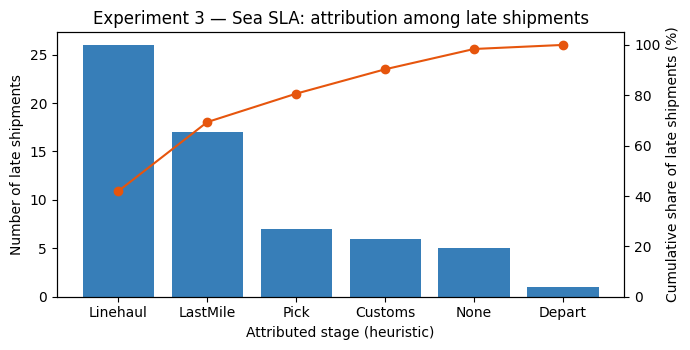

In [7]:
SEA_SLA_DAYS = 18  # <-- CHANGE HERE: 18 -> 20 days
sla_after = change_sea_sla(baseline, SEA_SLA_DAYS)
compare(baseline, sla_after, "Experiment 3 — Sea SLA")  # <-- OBSERVE OUTPUT

**THINK**

1. How do Sea and overall simplified OTIF change?
2. Have deliveries become physically faster?
3. Why can the Pareto counts change even when per-row RootCause labels do not?

**Your answers:**

1. ...
2. ...
3. ...

## Experiment 4 — Process improvement
**Business question:** What changes when upstream stages take less time?

**BEFORE:** Pick and Depart unchanged (0% reduction).

**CHANGE:** Change WAREHOUSE_REDUCTION from 0.00 to 0.20. Multiply both Pick and Depart by 0.8 for every row, record to 0.01 day, and recalculate all derived fields. Customs, Linehaul and LastMile remain fixed.

**AFTER:** Inspect the signed KPI comparison, per-mode table, attribution-count comparison and updated Pareto.

Experiment 4 — Pick and Depart


,BEFORE,AFTER,Difference (AFTER - BEFORE),Difference unit
Shipments,500.00,500.00,0.0,shipments
Late shipments,62.00,62.00,0.0,shipments
Late rate (%),12.40,12.40,0.0,percentage points
OTIF (%),87.60,87.60,0.0,percentage points
Mean lead time (days),6.66,6.66,0.0,days


AFTER: results by mode


,Shipments,Late_shipments,Mean_lead_time_days,Mean_SLA_days,OTIF_pct
Mode,,,,,
Air,102,41,3.83,4.0,59.80
Road,294,8,4.99,7.0,97.28
Sea,104,13,14.15,18.0,87.50


Attribution counts among late shipments (denominator can change)


,BEFORE late count,AFTER late count,Difference
Attributed stage,,,
Linehaul,26,26,0
LastMile,17,17,0
Pick,7,7,0
Customs,6,6,0
None,5,5,0
Depart,1,1,0


AFTER: sorted Pareto table


,Attributed stage,Late shipments,Share of late shipments (%),Cumulative share (%)
0,Linehaul,26,41.94,41.94
1,LastMile,17,27.42,69.35
2,Pick,7,11.29,80.65
3,Customs,6,9.68,90.32
4,None,5,8.06,98.39
5,Depart,1,1.61,100.00


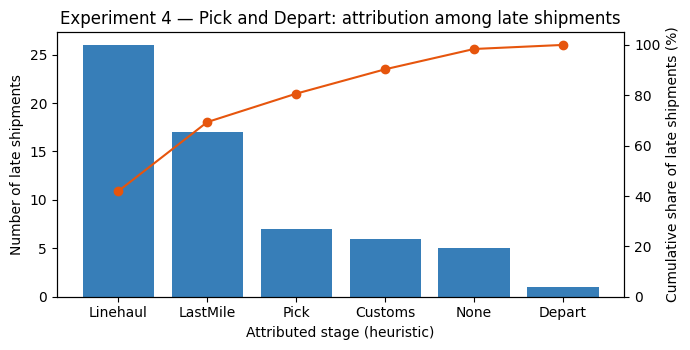

In [8]:
WAREHOUSE_REDUCTION = 0.0  # <-- CHANGE HERE: 0.00 -> 0.20 (20%)
warehouse_after = improve_warehouse(baseline, WAREHOUSE_REDUCTION)
compare(baseline, warehouse_after, "Experiment 4 — Pick and Depart")  # <-- OBSERVE OUTPUT

**THINK**

1. How much does average lead time decrease?
2. How do late count and attribution frequencies change?
3. Does this model change downstream stage durations, or only total elapsed lead time?

**Your answers:**

1. ...
2. ...
3. ...

## Experiment 5 — Late definition change
**Business question:** How does a reporting tolerance change the late population?

**BEFORE:** Strict rule: LeadTime > SLA (zero tolerance).

**CHANGE:** Change LATE_TOLERANCE_DAYS from 0 to 1. The rule becomes LeadTime > SLA + 1. Preserve Late_Strict; recalculate Late and the tolerance-adjusted OTIF. Physical durations, SLA and per-row RootCause labels do not change.

**AFTER:** Inspect the signed KPI comparison, per-mode table, attribution-count comparison and updated Pareto.

Experiment 5 — Late tolerance


,BEFORE,AFTER,Difference (AFTER - BEFORE),Difference unit
Shipments,500.00,500.00,0.0,shipments
Late shipments,62.00,62.00,0.0,shipments
Late rate (%),12.40,12.40,0.0,percentage points
OTIF (%),87.60,87.60,0.0,percentage points
Mean lead time (days),6.66,6.66,0.0,days


AFTER: results by mode


,Shipments,Late_shipments,Mean_lead_time_days,Mean_SLA_days,OTIF_pct
Mode,,,,,
Air,102,41,3.83,4.0,59.80
Road,294,8,4.99,7.0,97.28
Sea,104,13,14.15,18.0,87.50


Attribution counts among late shipments (denominator can change)


,BEFORE late count,AFTER late count,Difference
Attributed stage,,,
Linehaul,26,26,0
LastMile,17,17,0
Pick,7,7,0
Customs,6,6,0
None,5,5,0
Depart,1,1,0


AFTER: sorted Pareto table


,Attributed stage,Late shipments,Share of late shipments (%),Cumulative share (%)
0,Linehaul,26,41.94,41.94
1,LastMile,17,27.42,69.35
2,Pick,7,11.29,80.65
3,Customs,6,9.68,90.32
4,None,5,8.06,98.39
5,Depart,1,1.61,100.00


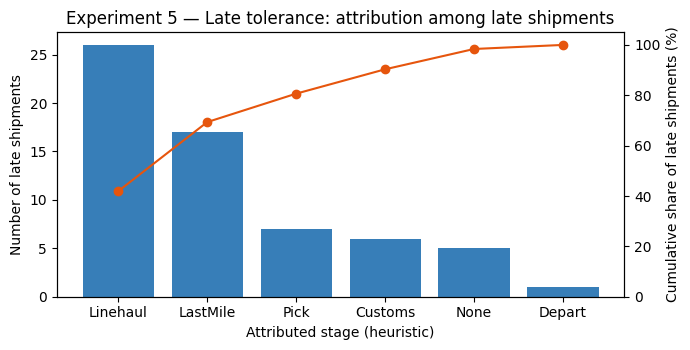

In [9]:
LATE_TOLERANCE_DAYS = 0  # <-- CHANGE HERE: 0 -> 1 day
tolerance_after = evaluate(baseline, tolerance_days=LATE_TOLERANCE_DAYS)
compare(baseline, tolerance_after, "Experiment 5 — Late tolerance")  # <-- OBSERVE OUTPUT

**THINK**

1. How many shipments leave the late population?
2. Why can the attribution distribution change without removing any physical delays?
3. Why must this result be labeled tolerance-adjusted rather than strict SLA compliance?

**Your answers:**

1. ...
2. ...
3. ...

## Final comparison
Summarize all five experiments. Distinguish a change to physical stage durations from a change to the reporting rule.

| Experiment | Parameter change | OTIF change (percentage points) | Physical duration or reporting change? | Attribution interpretation |
|---|---|---|---|---|
| 1 Customs | | | | |
| 2 Linehaul | | | | |
| 3 Sea SLA | | | | |
| 4 Pick/Depart | | | | |
| 5 Late definition | | | | |

**Reflection:** What additional evidence would you request before recommending an operational intervention?